In [1]:
import sympy as sp
import numpy as np
from scipy import optimize as opt
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [2]:
###DATA INLADEN
#moment van inspuiten 6.55: index 1863
#moment van inspuiten 7.4: index 1868
#pH 6.55
with open("pH6.55.txt", encoding = 'cp1252') as f:
    lines = f.readlines()
    data_lines = lines[2:]
    data_lines = [line.replace(",", ".") for line in data_lines]
    data_655 = np.loadtxt(data_lines, delimiter="\t").T

t_655 = data_655[0] - 1863 #herschalen naar inspuitmoment
results = {}
for flask in range(4):
    base = 1 + flask * 8
    T1 = data_655[base]
    T2 = data_655[base + 2]
    P = data_655[base + 4]
    Rth = data_655[base + 3]
    results[f"T1_655_{flask + 1}"] = T1
    results[f"P_655_{flask + 1}"] = P
    results[f"T2_655_{flask + 1}"] = T2
    results[f"Rth_655_{flask + 1}"] = Rth

#pH 7.4
with open("pH7.4.txt", encoding = 'cp1252') as f:
    lines = f.readlines()
    data_lines = lines[2:]
    data_lines = [line.replace(",", ".") for line in data_lines]
    data_74 = np.loadtxt(data_lines, delimiter="\t").T

t_74 = data_74[0] - 1868 #herschalen naar inspuiten
for flask in range(4):
    base = 1 + flask * 8
    T1 = data_74[base]
    T2 = data_74[base + 2]
    P = data_74[base + 4]
    Rth = data_74[base + 3]
    results[f"T1_74_{flask + 1}"] = T1
    results[f"P_74_{flask + 1}"] = P
    results[f"T2_74_{flask + 1}"] = T2
    results[f"Rth_74_{flask + 1}"] = Rth

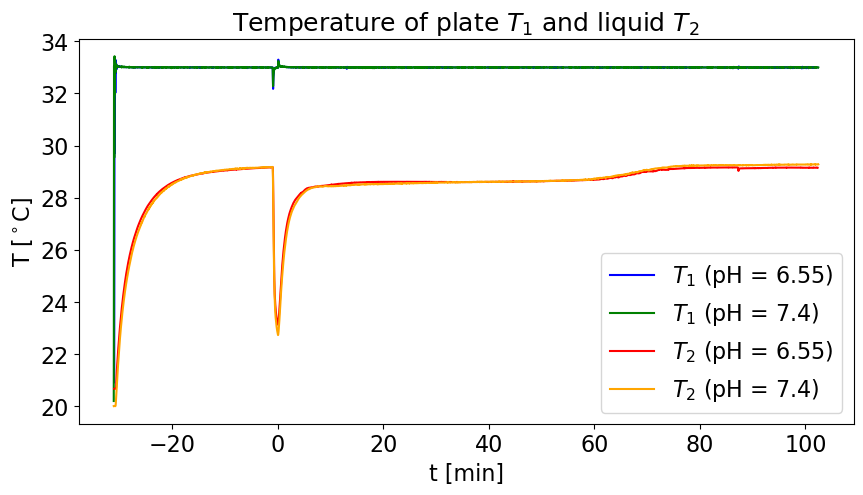

In [3]:
###RUWE DATA PLOTTEN
#T1 & T2
T1_gem_655 = np.mean([results[f"T1_655_{i}"] for i in range(1, 5)], axis = 0)
T2_gem_655 = np.mean([results[f"T2_655_{i}"] for i in range(1, 5)], axis = 0)
T1_gem_74 = np.mean([results[f"T1_74_{i}"] for i in [1, 3, 4]], axis = 0)
T2_gem_74 = np.mean([results[f"T2_74_{i}"] for i in [1, 3, 4]], axis = 0)

fig, ax = plt.subplots(figsize = (10, 5))
ax.plot(t_655[:8001]/60, T1_gem_655[:8001], label = r'$T_1$ (pH = 6.55)', color = 'blue')
ax.plot(t_74[:8001]/60, T1_gem_74[:8001], label = r'$T_1$ (pH = 7.4)', color = 'green')
ax.plot(t_655[:8001]/60, T2_gem_655[:8001], label = r'$T_2$ (pH = 6.55)', color = 'red')
ax.plot(t_74[:8001]/60, T2_gem_74[:8001], label = r'$T_2$ (pH = 7.4)', color = 'orange')

ax.tick_params(axis='both', which='major', labelsize=16)
ax.set_xlabel('t [min]', fontsize = 16)
ax.set_ylabel(r'T [$^\circ$C]', fontsize = 16)
ax.set_title(r'Temperature of plate $T_1$ and liquid $T_2$', fontsize = 18)
ax.legend(fontsize = 16)

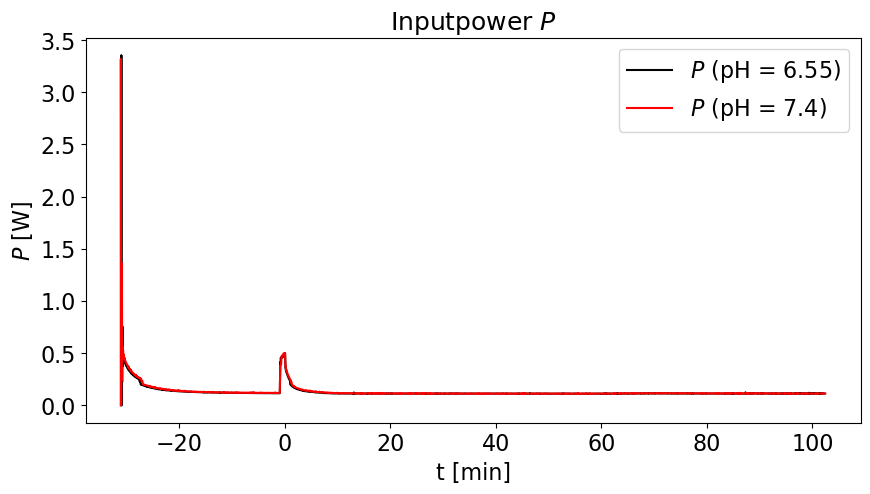

In [4]:
fontsize = 16#Power
P_gem_655 = np.mean([results[f"P_655_{i}"] for i in range(1, 5)], axis = 0)
P_gem_74 = np.mean([results[f"P_74_{i}"] for i in [1, 3, 4]], axis = 0)

fig, ax = plt.subplots(figsize = (10, 5))
ax.plot(t_655[:8001]/60, P_gem_655[:8001], label = r'$P$ (pH = 6.55)', color = 'black')
ax.plot(t_74[:8001]/60, P_gem_74[:8001], label = r'$P$ (pH = 7.4)', color = 'red')

ax.tick_params(axis='both', which='major', labelsize=16)
ax.set_xlabel('t [min]', fontsize = 16)
ax.set_ylabel(r'$P$ [W]', fontsize = 16)
ax.set_title(r'Inputpower $P$', fontsize = 18)
ax.legend(fontsize = 16)

1612


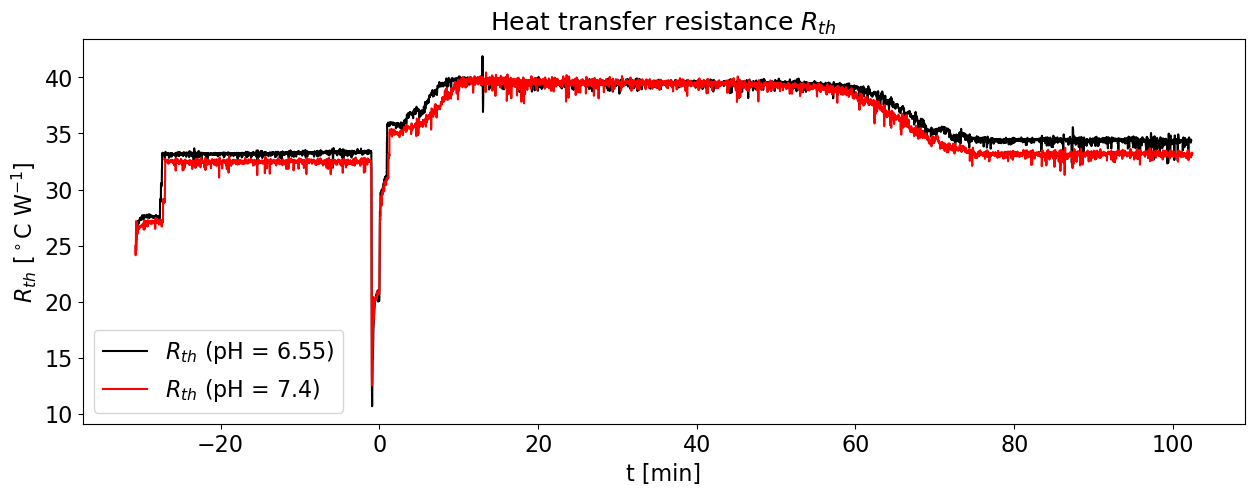

In [5]:
#Rth
Rth_gem_655 = np.mean([results[f"Rth_655_{i}"] for i in range(1, 5)], axis = 0)
Rth_gem_74 = np.mean([results[f"Rth_74_{i}"] for i in [1, 3, 4]], axis = 0)

fig, ax = plt.subplots(figsize = (15, 5))
ax.plot(t_655[25:8001]/60, Rth_gem_655[25:8001], label = r'$R_{th}$ (pH = 6.55)', color = 'black')
ax.plot(t_74[25:8001]/60, Rth_gem_74[25:8001], label = r'$R_{th}$ (pH = 7.4)', color = 'red')

ax.tick_params(axis='both', which='major', labelsize=16)
ax.set_xlabel('t [min]', fontsize = 16)
ax.set_ylabel(r'$R_{th}$ [$^\circ$C W$^{-1}$]', fontsize = 16)
ax.set_title(r'Heat transfer resistance $R_{th}$', fontsize = 18)
ax.legend(fontsize = 16, loc = 'lower left')
print(np.argmin(Rth_gem_74[200:8001]))

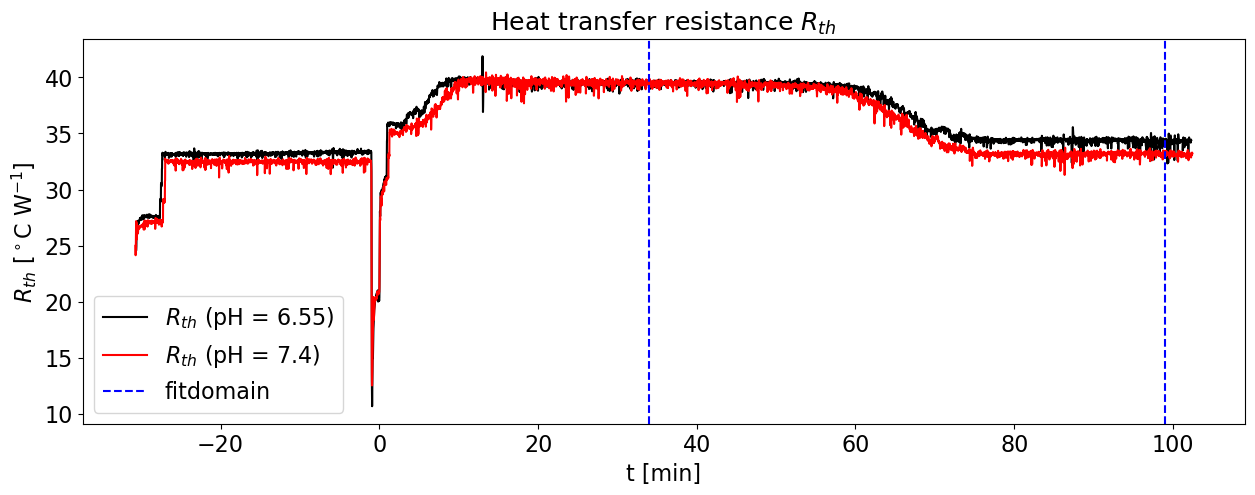

In [6]:
#Rth - verticale streep
fig, ax = plt.subplots(figsize = (15, 5))
ax.plot(t_655[25:8001]/60, Rth_gem_655[25:8001], label = r'$R_{th}$ (pH = 6.55)', color = 'black')
ax.plot(t_74[25:8001]/60, Rth_gem_74[25:8001], label = r'$R_{th}$ (pH = 7.4)', color = 'red')

ax.tick_params(axis='both', which='major', labelsize=16)
ax.set_xlabel('t [min]', fontsize = 16)
ax.set_ylabel(r'$R_{th}$ [$^\circ$C W$^{-1}$]', fontsize = 16)
ax.set_title(r'Heat transfer resistance $R_{th}$', fontsize = 18)
ax.axvline(t_655[65*60]/60, label = 'fitdomain', color = 'blue', ls = '--')
ax.axvline(t_655[130*60]/60, color = 'blue', ls = '--')
ax.legend(fontsize = 16)

C:\Users\quint\AppData\Local\Temp\ipykernel_26972\1500125455.py:3: RuntimeWarning: overflow encountered in exp
  return Rfin + (Rin - Rfin) / (1 + np.exp((t - td50) / deltat))


Optimized parameters: [3963.5494617   152.0610418    39.45633156   34.37780139]
Their errors: [2.77182043 1.89655115 0.00632674 0.00443176]


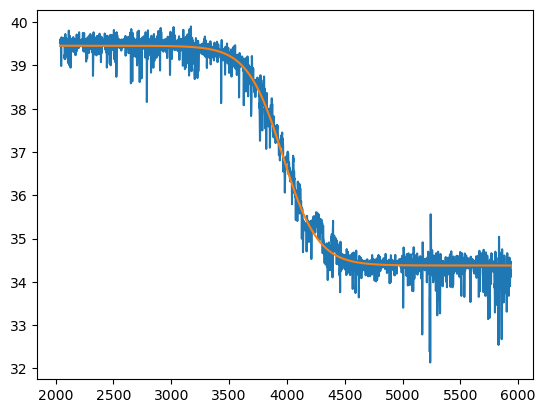

In [7]:
###FITTEN
def sigmoid(t, td50, deltat, Rin, Rfin):
    return Rfin + (Rin - Rfin) / (1 + np.exp((t - td50) / deltat))

begin = 65 * 60
eind = 130 * 60

#pH 6.55
Rth_std_655 = np.std([results[f"Rth_655_{i}"] for i in range(1, 5)], axis = 0, ddof = 1)

popt, pcov = opt.curve_fit(sigmoid, t_655[begin:eind], Rth_gem_655[begin:eind], [2900, 1, Rth_gem_655[begin], Rth_gem_655[eind]], Rth_std_655[begin:eind])

Y = popt[3] + (popt[2] - popt[3]) / (1 + np.exp((t_655[begin:eind] - popt[0]) / popt[1]))

td50_655 = popt[0]
std50_655 = np.sqrt(np.diag(pcov))[0]

plt.plot(t_655[begin:eind], Rth_gem_655[begin:eind])
plt.plot(t_655[begin:eind], Y)
print("Optimized parameters:", popt)
print("Their errors:", np.sqrt(np.diag(pcov)))

C:\Users\quint\AppData\Local\Temp\ipykernel_26972\1500125455.py:3: RuntimeWarning: overflow encountered in exp
  return Rfin + (Rin - Rfin) / (1 + np.exp((t - td50) / deltat))


Optimized parameters: [3916.61460459  193.36642963   39.40988374   33.09151311]
Their errors: [2.43625973 1.83500428 0.00883046 0.00687523]


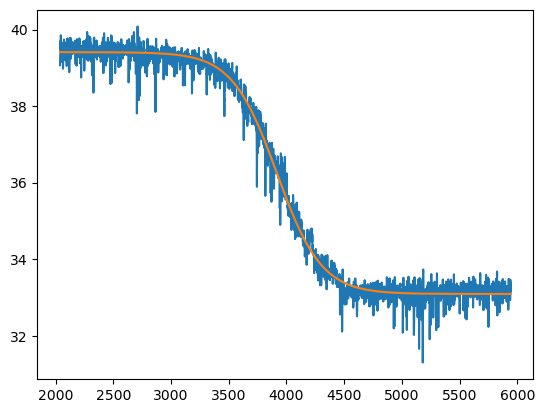

In [8]:
#pH 7.4
Rth_std_74 = np.std([results[f"Rth_74_{i}"] for i in [1, 3, 4]], axis = 0)

popt, pcov = opt.curve_fit(sigmoid, t_74[begin:eind], Rth_gem_74[begin:eind], [2900, 1, Rth_gem_74[begin], Rth_gem_74[eind]], Rth_std_74[begin:eind])

Y = popt[3] + (popt[2] - popt[3]) / (1 + np.exp((t_74[begin:eind] - popt[0]) / popt[1]))

td50_74 = popt[0]
std50_74 = np.sqrt(np.diag(pcov))[0]

plt.plot(t_74[begin:eind], Rth_gem_74[begin:eind])
plt.plot(t_74[begin:eind], Y)
print("Optimized parameters:", popt)
print("Their errors:", np.sqrt(np.diag(pcov)))

Text(0.5, 1.0, "Cell detachment time for different pH's")

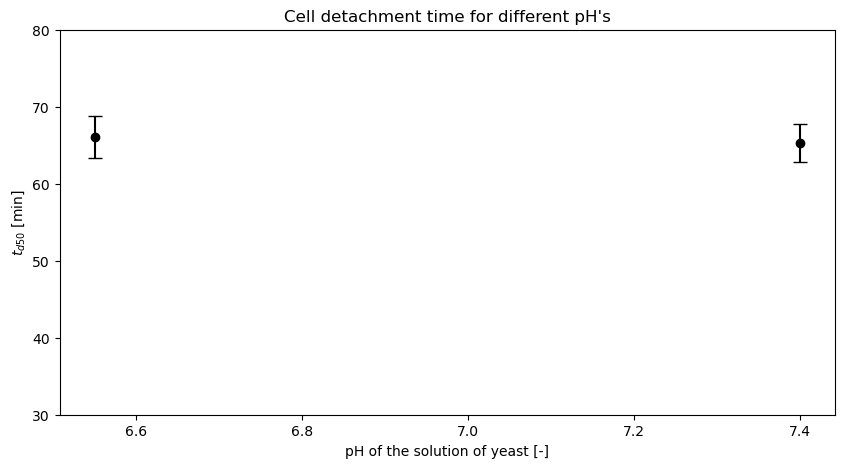

In [9]:
fig, ax = plt.subplots(figsize = (10, 5))
tijden = np.array([td50_655, td50_74])/60
pH = [6.55, 7.4]
errors = [std50_655, std50_74]
for i in range(2):
    ax.errorbar(pH[i], tijden[i], yerr = errors[i], color = 'black', capsize = 5, marker = 'o')

ax.set_ylim(30, 80)

ax.set_xlabel("pH of the solution of yeast [-]")
ax.set_ylabel(r'$t_{d50}$ [min]')
ax.set_title(r"Cell detachment time for different pH's")

C:\Users\quint\AppData\Local\Temp\ipykernel_26972\3272988678.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x = 'pH of the yeast solution [-]', y = r'Detachment time $t_{d50}$ [min]', data = df, palette = 'viridis', capsize = 0.1)


Text(0.5, 1.0, '$t_{d50}$ per pH')

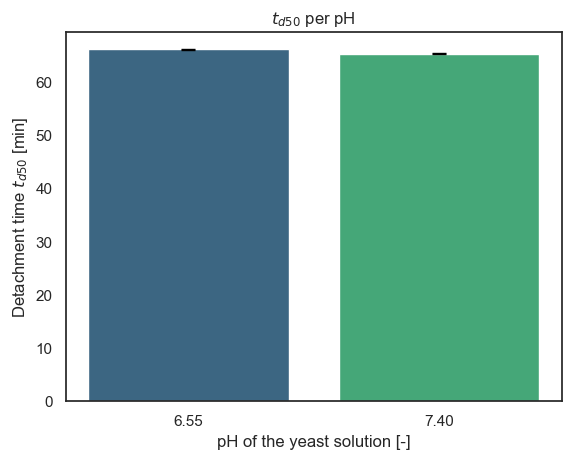

In [10]:
data = {
    'pH of the yeast solution [-]': ['6.55', '7.40'],
    r'Detachment time $t_{d50}$ [min]': np.array([td50_655, td50_74])/60,
    'Error': np.array([std50_655, std50_74])/60
}
df = pd.DataFrame(data)

sns.set_theme(style="white")
ax = sns.barplot(x = 'pH of the yeast solution [-]', y = r'Detachment time $t_{d50}$ [min]', data = df, palette = 'viridis', capsize = 0.1)
ax.errorbar( x=df['pH of the yeast solution [-]'], y=df[r'Detachment time $t_{d50}$ [min]'], yerr=df['Error'], fmt='none', ecolor='black', capsize=5)
ax.set_title(r'$t_{d50}$ per pH')